# Advanced World Happiness Tutorial

This notebook serves as a comprehensive tutorial for the advanced project on the World Happiness Report dataset. It connects all the elements from the plan: data loading (software engineering), in-depth EDA with nice plots (data analysis), advanced modeling including stacking, optimization, forecasting, and explainable AI (data science), and mathematical implementations with explanations (math). The code is imported from the modular package structure for reusability.
We'll proceed step by step, with explanations, code execution, and outputs where applicable. Assume you've set up the repository as described, with datasets in data/. Run this in Jupyter Notebook or Lab.

## Setup and Imports

In [3]:
import os

import sys, os
sys.path.append(os.path.abspath(".."))
print(f'System path updated: {sys.path}')

System path updated: ['/opt/anaconda3/lib/python313.zip', '/opt/anaconda3/lib/python3.13', '/opt/anaconda3/lib/python3.13/lib-dynload', '', '/Users/abdulibrahim/Documents/gitHub/world-happiness/WHenv/lib/python3.13/site-packages', '/Users/abdulibrahim/Documents/gitHub/world-happiness/src', '/Users/abdulibrahim/Documents/gitHub/world-happiness']


In [4]:
import pandas as pd
import numpy as np
from src.world_happiness.dataloader import DataLoader
from src.world_happiness.eda import perform_eda
from src.world_happiness.models import HappinessModel
from src.world_happiness.math_utils import gradient_descent_from_scratch, apply_svd, bayesian_inference

# For reproducibility
np.random.seed(42)

/Users/abdulibrahim/Documents/gitHub/world-happiness/WHenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Loading and Preprocessing

In [4]:

os.getcwd()

'/Users/abdulibrahim/Documents/gitHub/world-happiness/notebooks'

In [5]:
# Initialize and load data
loader = DataLoader(data_dir='../data/')
df = loader.load_data()

# Preprocess (scaling)
df = loader.preprocess()

# Display head for verification
print("Loaded and Preprocessed DataFrame:")
display(df.head())

2025-09-03 00:19:49,625 - WARNING - File for 2020 not found.
2025-09-03 00:19:49,626 - WARNING - File for 2021 not found.
2025-09-03 00:19:49,626 - WARNING - File for 2022 not found.
2025-09-03 00:19:49,626 - WARNING - File for 2023 not found.
2025-09-03 00:19:49,627 - WARNING - File for 2024 not found.


2025-09-03 00:19:49,627 - WARNING - File for 2025 not found.
2025-09-03 00:19:49,634 - INFO - Loaded data for 5 years with shape (782, 18)


Loaded and Preprocessed DataFrame:


,Country,Region,Happiness Rank,Happiness Score,Standard Error,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Perceptions of corruption,Generosity,Dystopia + residual,Year,Lower Confidence Interval,Upper Confidence Interval,Whisker.high,Whisker.low,Overall rank
0,Switzerland,Western Europe,-2.221368,1.959628,-1.354748,1.180267,0.823221,1.325870,1.665629,2.785442,0.639746,0.967462,2015,-0.017763,-0.024877,-0.03279,-0.024374,0.0
1,Iceland,Western Europe,-2.192851,1.936552,0.523054,0.948887,0.983300,1.351701,1.424764,0.151941,1.781084,1.388845,2015,-0.017763,-0.024877,-0.03279,-0.024374,0.0
2,Denmark,Western Europe,-2.164335,1.906377,-1.460558,1.005780,0.856834,1.056718,1.559661,3.389010,1.004676,0.909628,2015,-0.017763,-0.024877,-0.03279,-0.024374,0.0
3,Norway,Western Europe,-2.135818,1.901939,-0.756860,1.333775,0.766865,1.099313,1.692857,2.267409,1.050487,0.848622,2015,-0.017763,-0.024877,-0.03279,-0.024374,0.0
4,Canada,North America,-2.107302,1.817625,-1.173725,1.007770,0.741542,1.181602,1.452254,1.931894,1.959500,0.817697,2015,-0.017763,-0.024877,-0.03279,-0.024374,0.0


# Data Analysis (In-Depth EDA)

       Happiness Rank  Happiness Score  Standard Error  GDP per capita  \
count    7.820000e+02     7.820000e+02    7.820000e+02    7.820000e+02   
mean     1.817245e-17    -6.905530e-16    1.290244e-15   -2.271556e-16   
std      1.000640e+00     1.000640e+00    1.000640e+00    1.000640e+00   
min     -2.221368e+00    -2.383894e+00   -3.347284e+00   -2.250291e+00   
25%     -3.677969e-01    -7.714925e-01   -1.016054e-01   -7.604102e-01   
50%      2.917286e-03    -5.060452e-02   -1.016054e-01    1.625167e-01   
75%      3.736314e-01     7.193190e-01   -1.016054e-01    7.864300e-01   
max      2.255719e+00     2.121157e+00    1.175290e+01    2.898579e+00   

       Social support  Healthy life expectancy  Freedom to make life choices  \
count    7.820000e+02             7.820000e+02                  7.820000e+02   
mean    -9.086224e-17            -2.271556e-17                  2.998454e-16   
std      1.000640e+00             1.000640e+00                  1.000640e+00   
min     -3.27

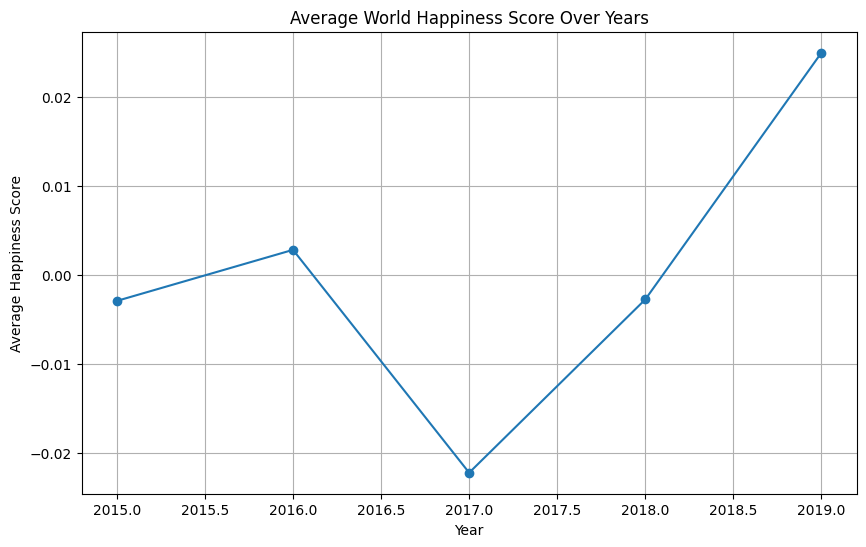

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [6]:
# Run EDA function

perform_eda(df)

## Data Science

2025-09-03 00:20:11,237 - INFO - Stacked model R2: 0.7648929889177388
[I 2025-09-03 00:20:11,238] A new study created in memory with name: no-name-011ab2a1-7326-40e8-ab5e-c3c63c66dfaa


Stacked Model R2 Score: 0.7648929889177388


[I 2025-09-03 00:20:12,384] Trial 0 finished with value: 0.7792522900239922 and parameters: {'n_estimators': 190, 'max_depth': 19}. Best is trial 0 with value: 0.7792522900239922.
[I 2025-09-03 00:20:13,438] Trial 1 finished with value: 0.7784923002724072 and parameters: {'n_estimators': 175, 'max_depth': 17}. Best is trial 0 with value: 0.7792522900239922.
[I 2025-09-03 00:20:14,191] Trial 2 finished with value: 0.7782696739718653 and parameters: {'n_estimators': 130, 'max_depth': 12}. Best is trial 0 with value: 0.7792522900239922.
[I 2025-09-03 00:20:15,014] Trial 3 finished with value: 0.7697531047367849 and parameters: {'n_estimators': 191, 'max_depth': 6}. Best is trial 0 with value: 0.7792522900239922.
[I 2025-09-03 00:20:15,505] Trial 4 finished with value: 0.7770920926147353 and parameters: {'n_estimators': 80, 'max_depth': 17}. Best is trial 0 with value: 0.7792522900239922.
[I 2025-09-03 00:20:16,578] Trial 5 finished with value: 0.7785856287386566 and parameters: {'n_estima

Forecasted Happiness for Finland (next 5 years): 5    2.168552
6    2.190883
7    2.201405
8    2.206363
9    2.208699
Name: predicted_mean, dtype: float64


/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/models.py:122: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



NameError: name 'plt' is not defined

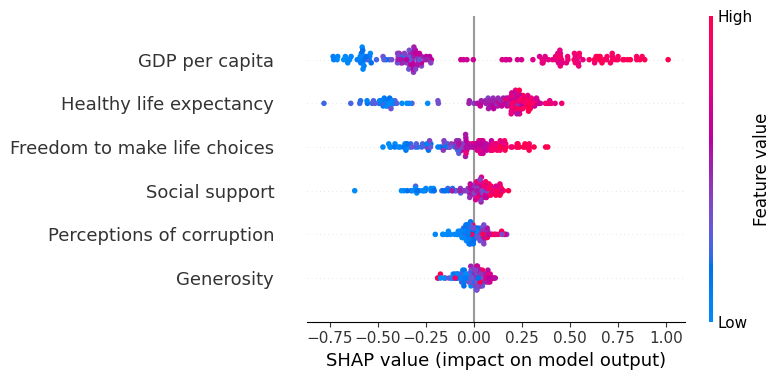

In [7]:
# Initialize model
model = HappinessModel(df)

# Stacking models and evaluate
r2_score_stacked = model.stack_models()
print(f"Stacked Model R2 Score: {r2_score_stacked}")

# Hyperparameter optimization with Optuna
model.run_optuna(n_trials=20)  # Adjust trials as needed

# Time-series forecasting for a country
model.time_series_forecast(country='Finland')

# Train a RF for SHAP (example)
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(random_state=42).fit(model.X_train, model.y_train)

# Explainable AI
model.explainable_ai(rf_model)  # Saves 'shap_summary.png'

### Gradient Descent from Scratch

In [8]:
# Prepare data (add bias)
X_np = np.c_[np.ones(model.X.shape[0]), model.X.values]
y_np = model.y.values

# Run GD
theta = gradient_descent_from_scratch(X_np, y_np, lr=0.01, epochs=1000)
print("Optimized Theta (intercept, coefficients):", theta)

Optimized Theta (intercept, coefficients): [-6.25784147e-16  4.01126087e-01  1.89771915e-01  2.32413885e-01
  1.98715488e-01  6.37733727e-02  8.25211063e-02]


/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/math_utils.py:17: RuntimeWarning:

divide by zero encountered in matmul

/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/math_utils.py:17: RuntimeWarning:

overflow encountered in matmul

/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/math_utils.py:17: RuntimeWarning:

invalid value encountered in matmul



### SVD for Dimensionality Reduction

In [9]:
# Run SVD

reduced_matrix = apply_svd(df, k=3)
print("Reduced Matrix Sample:", reduced_matrix[:5])

Singular values: [60.12516281 39.83217277 37.86025531 33.34783945 28.25227123 25.36124782
 22.29740767 22.08615514 17.05961361 16.48385612 12.80952873  6.67222442
  1.28278893  1.23816071]
Variance explained by top 3 components: 0.61
Reduced Matrix Sample: [[-1.16721198 -0.22762878  1.39584497  1.20593154  1.34623386  1.04333076
   0.79168821  0.27975141  0.15731608  0.80302256  0.79696308  0.68831415
   0.69002497 -0.92173997]
 [-1.11214556 -0.12431862  1.01254905  0.82881923  0.95496642  0.73653929
   0.56568741  0.19773595  0.39649333  0.78912853  0.78674066  0.71539194
   0.71655191 -0.44926125]
 [-1.13609638 -0.22908166  1.38426876  1.19940581  1.33685955  1.0363922
   0.78602754  0.27790419  0.13368804  0.78449752  0.77832845  0.66013915
   0.66184412 -0.93213237]
 [-1.10773008 -0.2116663   1.30989245  1.12973882  1.26228647  0.97807045
   0.74234852  0.26223488  0.16038298  0.75891281  0.75331815  0.6605011
   0.66210118 -0.85445286]
 [-1.05026816 -0.19984498  1.23900692  1.0680

/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/math_utils.py:35: RuntimeWarning:

divide by zero encountered in matmul

/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/math_utils.py:35: RuntimeWarning:

overflow encountered in matmul

/Users/abdulibrahim/Documents/gitHub/world-happiness/src/world_happiness/math_utils.py:35: RuntimeWarning:

invalid value encountered in matmul



### Bayesian Inference

In [10]:
# Run Bayesian inference approximation

bayesian_inference(df)

                            OLS Regression Results                            
Dep. Variable:        Happiness Score   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     1289.
Date:                Wed, 03 Sep 2025   Prob (F-statistic):          2.21e-167
Time:                        00:20:49   Log-Likelihood:                -728.22
No. Observations:                 782   AIC:                             1460.
Df Residuals:                     780   BIC:                             1470.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const          -6.349e-16      0.022  -2.89e